<a href="https://colab.research.google.com/github/MiguelFigueroa02/ITAM_Sport_Lucho_FC/blob/main/notebooks/04_model_XGOT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install mplsoccer

In [ ]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch, VerticalPitch
from google.colab import drive
import plotly.express as px
import plotly.graph_objects as go
import warnings
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, auc


In [ ]:
events_clean_ctx = pd.read_csv('/content/drive/MyDrive/ITAM_Hackathon/events_clean_ctx.csv')

/tmp/ipykernel_63822/3295965152.py:1: DtypeWarning: Columns (60,111,112,114) have mixed types. Specify dtype option on import or set low_memory=False.
  events_clean_ctx = pd.read_csv('/content/drive/MyDrive/ITAM_Hackathon/events_clean_ctx.csv')


In [ ]:
events_clean_ctx.columns.to_list()

['id',
 'index',
 'match_id',
 'period',
 'timestamp',
 'minute',
 'second',
 'event_type_id',
 'event_type_name',
 'possession',
 'possession_team_id',
 'possession_team_name',
 'play_pattern_id',
 'play_pattern_name',
 'team_id',
 'team_name',
 'player_id',
 'player_name',
 'player_position_id',
 'player_position_name',
 'location_x',
 'location_y',
 'end_location_x',
 'end_location_y',
 'end_location_z',
 'impact_height',
 'duration',
 'under_pressure',
 'counterpress',
 'substituted_player_id',
 'substituted_player_name',
 'pass_recipient_id',
 'pass_recipient_name',
 'pass_length',
 'pass_angle',
 'pass_height_id',
 'pass_height_name',
 'pass_cross',
 'pass_cut_back',
 'pass_switch',
 'assisted_shot_id',
 'key_pass_id',
 'follows_dribble',
 'one_on_one',
 'open_goal',
 'statsbomb_xg',
 'off_camera',
 'out',
 'obv_for_after',
 'obv_for_before',
 'obv_for_net',
 'obv_against_after',
 'obv_against_before',
 'obv_against_net',
 'obv_total_net',
 'outcome_id',
 'outcome_name',
 'type_i

In [ ]:
df = events_clean_ctx[events_clean_ctx['event_type_name']=='Shot']

In [ ]:
df[['player_id', 'player_name']]

,player_id,player_name
71,6357.0,Jonathan dos Santos Ramírez
246,13034.0,Sebastián Saucedo Mondragón
307,5556.0,Miguel Arturo Layún Prado
374,23842.0,Aitor García Flores
476,8863.0,Leonardo Gabriel Suárez
...,...,...
448711,43555.0,Erick Daniel Sánchez Ocegueda
448758,30500.0,Kevin Nahin Álvarez Campos
448943,30736.0,Paul Brian Rodríguez Bravo
448999,337757.0,Miguel Ángel Vázquez García


In [ ]:
team_df = df[df.team_id ==1229]
jugadores_id = []
jugadores_name = []
for id, name in zip(team_df['player_id'], team_df['player_name']):
  if id not in jugadores_id:
    jugadores_id.append(id)
    jugadores_name.append(name)

In [ ]:
jugadores_df = pd.DataFrame({
    'player_id':jugadores_id,
    'player_name':jugadores_name
})

In [ ]:
jugadores_df.player_id = jugadores_df.player_id.astype(int)

In [ ]:
print(df.head().to_markdown())

|     | id                                   |   index |   match_id |   period | timestamp    |   minute |   second |   event_type_id | event_type_name   |   possession |   possession_team_id | possession_team_name   |   play_pattern_id | play_pattern_name   |   team_id | team_name   |   player_id | player_name                 |   player_position_id | player_position_name    |   location_x |   location_y |   end_location_x |   end_location_y |   end_location_z |   impact_height |   duration | under_pressure   | counterpress   |   substituted_player_id |   substituted_player_name |   pass_recipient_id |   pass_recipient_name |   pass_length |   pass_angle |   pass_height_id |   pass_height_name |   pass_cross |   pass_cut_back |   pass_switch |   assisted_shot_id | key_pass_id                          | follows_dribble   | one_on_one   | open_goal   |   statsbomb_xg | off_camera   | out   |   obv_for_after |   obv_for_before |   obv_for_net |   obv_against_after |   obv_against_before |

In [ ]:
df_tiros = df[['possession_team_name','play_pattern_name','player_id','player_position_name','location_x','location_y',
               'location_y','end_location_x','end_location_y','end_location_z','follows_dribble','one_on_one','open_goal','outcome_name','type_name',
               'technique_name','body_part_name','aerial_won','first_time','penalty','shot_execution_xg','shot_execution_xg_uplift','attacking_direction'
               ]]

In [ ]:
df_tiros.outcome_name.unique()

array(['Off T', 'Saved', 'Blocked', 'Goal', 'Wayward', 'Post',
       'Saved to Post', 'Saved Off Target'], dtype=object)

Creamos un modelado de goles del América

In [ ]:
df_team = df_tiros[(df_tiros.possession_team_name=='América')]

Tamaño estimado de la portería

In [ ]:
df_tiros[df_tiros.outcome_name=='Post'][['end_location_x','end_location_y','end_location_z']].describe()

,end_location_x,end_location_y,end_location_z
count,76.000000,76.000000,76.000000
mean,119.997368,39.818421,1.707895
std,0.016114,3.428536,1.194740
min,119.900000,35.500000,0.000000
25%,120.000000,36.200000,0.300000
50%,120.000000,38.750000,2.200000
75%,120.000000,43.900000,2.800000
max,120.000000,44.300000,3.000000


In [ ]:
remates = df_team[(df_team.end_location_y >=35.5) & (df_team.end_location_y<=44.3)&(df_team.end_location_z <=2.67)]

In [ ]:
remates.shape

(634, 23)

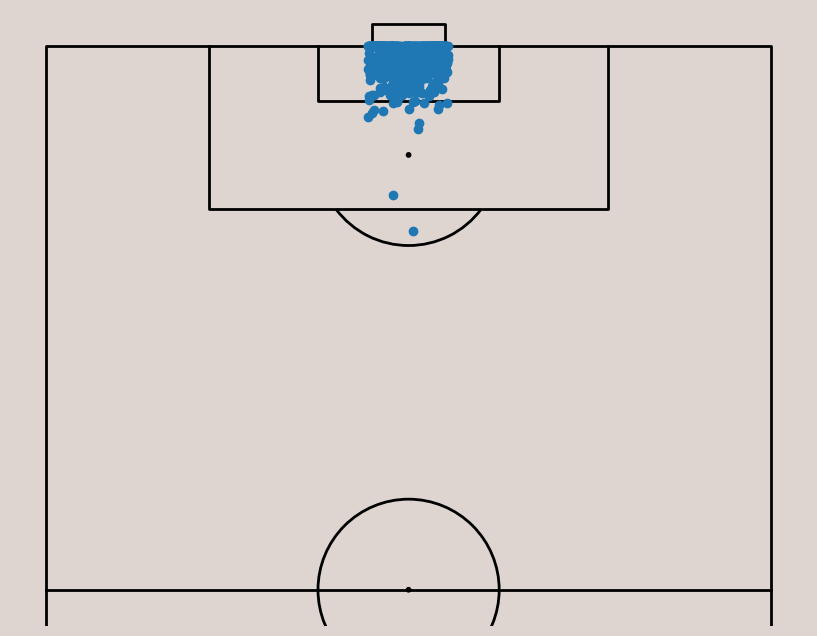

In [ ]:
fig, ax =  plt.subplots(figsize = (12,8))
fig.set_facecolor('#ded5d1')
pitch = VerticalPitch(
    pitch_type='statsbomb',
    goal_type='box',
    line_color='black',
    pitch_color='#ded5d1',
    half=True
)

pitch.draw(ax=ax)
pitch.scatter(remates.end_location_x, remates.end_location_y, ax=ax)

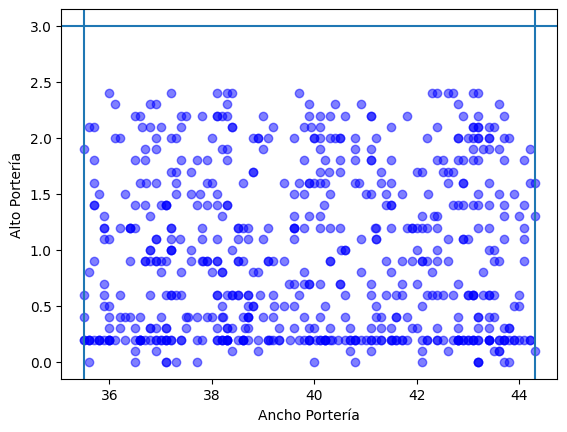

In [ ]:
plt.scatter(remates.end_location_y, remates.end_location_z, color='blue', label ='Tiros',alpha=0.5)
plt.xlabel('Ancho Portería')
plt.ylabel('Alto Portería')
plt.axhline(3.0)
plt.axvline(35.5)
plt.axvline(44.3)
plt.show()

Hacemos un tratamiento para entrenar el modelo

In [ ]:
remates.columns

Index(['possession_team_name', 'play_pattern_name', 'player_id',
       'player_position_name', 'location_x', 'location_y', 'location_y',
       'end_location_x', 'end_location_y', 'end_location_z', 'follows_dribble',
       'one_on_one', 'open_goal', 'outcome_name', 'type_name',
       'technique_name', 'body_part_name', 'aerial_won', 'first_time',
       'penalty', 'shot_execution_xg', 'shot_execution_xg_uplift',
       'attacking_direction'],
      dtype='object')

In [ ]:
remates.info()

<class 'pandas.core.frame.DataFrame'>
Index: 634 entries, 641 to 449074
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   possession_team_name      634 non-null    object 
 1   play_pattern_name         634 non-null    object 
 2   player_id                 634 non-null    float64
 3   player_position_name      634 non-null    object 
 4   location_x                634 non-null    float64
 5   location_y                634 non-null    float64
 6   location_y                634 non-null    float64
 7   end_location_x            634 non-null    float64
 8   end_location_y            634 non-null    float64
 9   end_location_z            634 non-null    float64
 10  follows_dribble           634 non-null    bool   
 11  one_on_one                634 non-null    object 
 12  open_goal                 634 non-null    object 
 13  outcome_name              634 non-null    object 
 14  type_name 

In [ ]:
print(remates.head().to_markdown())

|      | possession_team_name   | play_pattern_name   |   player_id | player_position_name      |   location_x |   location_y |   location_y |   end_location_x |   end_location_y |   end_location_z | follows_dribble   | one_on_one   | open_goal   | outcome_name   | type_name   | technique_name   | body_part_name   | aerial_won   | first_time   | penalty   |   shot_execution_xg |   shot_execution_xg_uplift | attacking_direction   |
|-----:|:-----------------------|:--------------------|------------:|:--------------------------|-------------:|-------------:|-------------:|-----------------:|-----------------:|-----------------:|:------------------|:-------------|:------------|:---------------|:------------|:-----------------|:-----------------|:-------------|:-------------|:----------|--------------------:|---------------------------:|:----------------------|
|  641 | América                | From Free Kick      |        8863 | Right Wing                |        108.5 |         63.2 |   

In [ ]:
df_modelo = remates.drop(columns=['possession_team_name'])

In [ ]:
df_modelo.player_id = df_modelo.player_id.astype(int).astype(str)

In [ ]:
print(df_modelo.head().to_markdown())

|      | play_pattern_name   |   player_id | player_position_name      |   location_x |   location_y |   location_y |   end_location_x |   end_location_y |   end_location_z | follows_dribble   | one_on_one   | open_goal   | outcome_name   | type_name   | technique_name   | body_part_name   | aerial_won   | first_time   | penalty   |   shot_execution_xg |   shot_execution_xg_uplift | attacking_direction   |
|-----:|:--------------------|------------:|:--------------------------|-------------:|-------------:|-------------:|-----------------:|-----------------:|-----------------:|:------------------|:-------------|:------------|:---------------|:------------|:-----------------|:-----------------|:-------------|:-------------|:----------|--------------------:|---------------------------:|:----------------------|
|  641 | From Free Kick      |        8863 | Right Wing                |        108.5 |         63.2 |         63.2 |            120   |             36.6 |              2.2 | False

In [ ]:
df_modelo.follows_dribble = df_modelo.follows_dribble.replace({True: 1, False: 0})

/tmp/ipykernel_63822/3961539746.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_modelo.follows_dribble = df_modelo.follows_dribble.replace({True: 1, False: 0})


In [ ]:
df_modelo.one_on_one = np.where(df_modelo.one_on_one == True,1,0)

In [ ]:
df_modelo.open_goal = np.where(df_modelo.open_goal == True,1,0)

In [ ]:
df_modelo['Goal']=np.where(df_modelo.outcome_name=='Goal', 1, 0)
df_modelo.drop(columns=['outcome_name'], inplace=True)

In [ ]:
df_modelo = df_modelo[df_modelo.type_name != 'Penalty']

In [ ]:
categoricas = []
for col in df_modelo.columns.unique().to_list():
  if str(df_modelo[col].dtypes) == 'object':
    print('Columna: ',col,'\n')
    print('Cantidad de resultados únicos:', df_modelo[col].nunique())
    print('Cantidad de resultados nulos:', df_modelo[col].isna().sum())
    print('Resultados únicos: \n', df_modelo[col].unique())
    print('--'*50, '\n')
    categoricas.append(col)

Columna:  play_pattern_name 

Cantidad de resultados únicos: 8
Cantidad de resultados nulos: 0
Resultados únicos: 
 ['From Free Kick' 'Regular Play' 'From Throw In' 'From Keeper'
 'From Corner' 'From Goal Kick' 'From Kick Off' 'From Counter']
---------------------------------------------------------------------------------------------------- 

Columna:  player_id 

Cantidad de resultados únicos: 45
Cantidad de resultados nulos: 0
Resultados únicos: 
 ['8863' '35544' '26369' '35375' '5556' '30500' '30736' '30458' '31956'
 '26288' '26256' '26400' '33097' '6357' '47467' '36167' '401174' '35690'
 '33126' '15822' '131189' '46322' '26312' '43555' '11388' '37999' '30944'
 '23428' '29265' '436702' '458388' '45608' '275553' '391381' '458389'
 '337757' '50763' '276020' '415002' '3016' '26774' '25458' '29574' '34349'
 '430674']
---------------------------------------------------------------------------------------------------- 

Columna:  player_position_name 

Cantidad de resultados únicos: 22
C

In [ ]:
categoricas

['play_pattern_name',
 'player_id',
 'player_position_name',
 'type_name',
 'technique_name',
 'body_part_name',
 'attacking_direction']

In [ ]:
df_modelo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 603 entries, 641 to 448711
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   play_pattern_name         603 non-null    object 
 1   player_id                 603 non-null    object 
 2   player_position_name      603 non-null    object 
 3   location_x                603 non-null    float64
 4   location_y                603 non-null    float64
 5   location_y                603 non-null    float64
 6   end_location_x            603 non-null    float64
 7   end_location_y            603 non-null    float64
 8   end_location_z            603 non-null    float64
 9   follows_dribble           603 non-null    int64  
 10  one_on_one                603 non-null    int64  
 11  open_goal                 603 non-null    int64  
 12  type_name                 603 non-null    object 
 13  technique_name            603 non-null    object 
 14  body_part_

In [ ]:
df_modelo.aerial_won = np.where(df_modelo.aerial_won == True,1,0)


In [ ]:
df_modelo.first_time = df_modelo.first_time.replace({True: 1, False: 0})

/tmp/ipykernel_63822/373872902.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_modelo.first_time = df_modelo.first_time.replace({True: 1, False: 0})


In [ ]:
df_modelo.drop(columns=['penalty'], inplace=True)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False), categoricas)
    ],
    remainder='passthrough'
)

In [ ]:
df_modelo_procesado= preprocessor.fit_transform(df_modelo)

In [ ]:
columnas_modelo= preprocessor.get_feature_names_out()

In [ ]:
df_procesado = pd.DataFrame(df_modelo_procesado,columns=columnas_modelo)

In [ ]:
print(df_procesado.head().to_markdown())

|    |   cat__play_pattern_name_From Corner |   cat__play_pattern_name_From Counter |   cat__play_pattern_name_From Free Kick |   cat__play_pattern_name_From Goal Kick |   cat__play_pattern_name_From Keeper |   cat__play_pattern_name_From Kick Off |   cat__play_pattern_name_From Throw In |   cat__play_pattern_name_Regular Play |   cat__player_id_11388 |   cat__player_id_131189 |   cat__player_id_15822 |   cat__player_id_23428 |   cat__player_id_25458 |   cat__player_id_26256 |   cat__player_id_26288 |   cat__player_id_26312 |   cat__player_id_26369 |   cat__player_id_26400 |   cat__player_id_26774 |   cat__player_id_275553 |   cat__player_id_276020 |   cat__player_id_29265 |   cat__player_id_29574 |   cat__player_id_3016 |   cat__player_id_30458 |   cat__player_id_30500 |   cat__player_id_30736 |   cat__player_id_30944 |   cat__player_id_31956 |   cat__player_id_33097 |   cat__player_id_33126 |   cat__player_id_337757 |   cat__player_id_34349 |   cat__player_id_35375 |   cat__player_id

In [ ]:
X = df_procesado.drop(columns=['remainder__Goal'])

In [ ]:
X.shape

(603, 103)

In [ ]:
print(X.dtypes)

cat__play_pattern_name_From Corner       float64
cat__play_pattern_name_From Counter      float64
cat__play_pattern_name_From Free Kick    float64
cat__play_pattern_name_From Goal Kick    float64
cat__play_pattern_name_From Keeper       float64
                                          ...   
remainder__open_goal                     float64
remainder__aerial_won                    float64
remainder__first_time                    float64
remainder__shot_execution_xg             float64
remainder__shot_execution_xg_uplift      float64
Length: 103, dtype: object


In [ ]:
y = df_procesado['remainder__Goal']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Modelo Random Forest

In [ ]:
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

In [ ]:
modelo_names = []
modelos_2_rs = []

In [ ]:
def modelos(modelo, modelo_name, X_train, y_train):
  modelo_names.append(modelo_name)
  metricas = ['accuracy', 'precision_macro','recall_macro', 'f1_macro']
  cv = cross_validate(
      modelo,
      X_train,
      y_train,
      cv=5,
      scoring=metricas
  )
  modelo_results = {
      'modelo':modelo_name
  }
  for metrica in metricas:
    scores = cv[f'test_{metrica}']
    print(f'Métrica: {metrica}')
    print('Score de cada Fold: \n', scores )
    print('Score promedio: \n', f'{scores.mean():.4f}')
    print('Desviación estándar del Score: ', f'{scores.std():.4f}')
    print('--'*20)
    modelo_results[f'scores_{metrica}'] = scores
    modelo_results[f'promedio_{metrica}']= scores.mean()

  modelos_2_rs.append(modelo_results)

modelos(modelo_rf, 'Random Forest', X_train, y_train)

Métrica: accuracy
Score de cada Fold: 
 [0.97938144 1.         1.         0.98958333 1.        ]
Score promedio: 
 0.9938
Desviación estándar del Score:  0.0083
----------------------------------------
Métrica: precision_macro
Score de cada Fold: 
 [0.97668269 1.         1.         0.99230769 1.        ]
Score promedio: 
 0.9938
Desviación estándar del Score:  0.0091
----------------------------------------
Métrica: recall_macro
Score de cada Fold: 
 [0.97668269 1.         1.         0.984375   1.        ]
Score promedio: 
 0.9922
Desviación estándar del Score:  0.0098
----------------------------------------
Métrica: f1_macro
Score de cada Fold: 
 [0.97668269 1.         1.         0.98818752 1.        ]
Score promedio: 
 0.9930
Desviación estándar del Score:  0.0093
----------------------------------------


In [ ]:
modelo_rf.fit(X_train, y_train)
y_pred=modelo_rf.predict(X_test)
y_prob= modelo_rf.predict_proba(X_test)

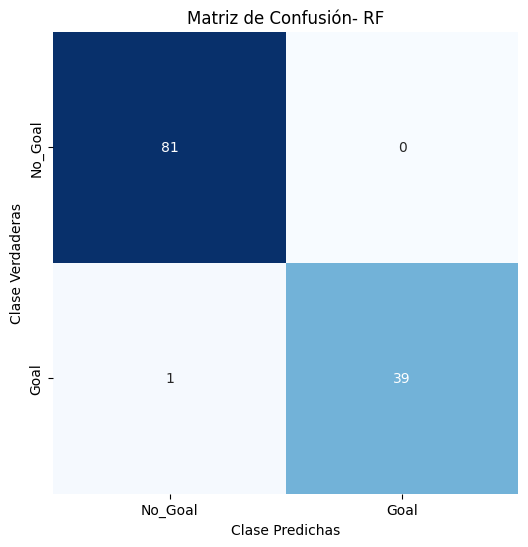

In [ ]:
target_names=['No_Goal', 'Goal']
cf_m = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,6))
sns.heatmap(cf_m, annot=True, fmt='d',cmap='Blues', cbar=False, xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Clase Predichas')
plt.ylabel('Clase Verdaderas')
plt.title('Matriz de Confusión- RF')
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay
y_pred_proba = modelo_rf.predict_proba(X_test)[:, 1]

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

In [ ]:
roc_auc = auc(fpr, tpr)

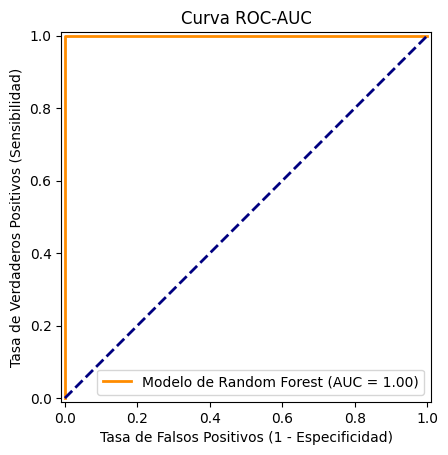

In [ ]:
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Modelo de Random Forest')
display.plot(color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('Curva ROC-AUC')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.show()


In [ ]:
y_pred_proba = modelo_rf.predict_proba(X)[:, 1]

In [ ]:
probabilities = pd.DataFrame(y_pred_proba, columns=['XGoT'])
X_with_prob = pd.concat([X.reset_index(drop=True), probabilities], axis=1)

In [ ]:
X_with_prob['dif'] = X_with_prob.XGoT - X_with_prob.remainder__shot_execution_xg
X_with_prob.dif.describe()

,dif
count,603.000000
mean,0.082951
std,0.317520
min,-0.856361
25%,-0.064479
50%,-0.011295
75%,0.154834
max,0.866905


In [ ]:
mas_prob = X_with_prob[X_with_prob.dif>0.35]
menos_prob =  X_with_prob[X_with_prob.dif<0]

In [ ]:
mas_prob.shape

(120, 105)

In [ ]:
menos_prob.shape

(345, 105)

In [ ]:
X_with_prob.columns

Index(['cat__play_pattern_name_From Corner',
       'cat__play_pattern_name_From Counter',
       'cat__play_pattern_name_From Free Kick',
       'cat__play_pattern_name_From Goal Kick',
       'cat__play_pattern_name_From Keeper',
       'cat__play_pattern_name_From Kick Off',
       'cat__play_pattern_name_From Throw In',
       'cat__play_pattern_name_Regular Play', 'cat__player_id_11388',
       'cat__player_id_131189',
       ...
       'remainder__end_location_z', 'remainder__follows_dribble',
       'remainder__one_on_one', 'remainder__open_goal',
       'remainder__aerial_won', 'remainder__first_time',
       'remainder__shot_execution_xg', 'remainder__shot_execution_xg_uplift',
       'XGoT', 'dif'],
      dtype='object', length=105)

In [ ]:
jugadores = X_with_prob[['cat__player_id_11388',
 'cat__player_id_131189',
 'cat__player_id_15822',
 'cat__player_id_23428',
 'cat__player_id_25458',
 'cat__player_id_26256',
 'cat__player_id_26288',
 'cat__player_id_26312',
 'cat__player_id_26369',
 'cat__player_id_26400',
 'cat__player_id_26774',
 'cat__player_id_275553',
 'cat__player_id_276020',
 'cat__player_id_29265',
 'cat__player_id_29574',
 'cat__player_id_3016',
 'cat__player_id_30458',
 'cat__player_id_30500',
 'cat__player_id_30736',
 'cat__player_id_30944',
 'cat__player_id_31956',
 'cat__player_id_33097',
 'cat__player_id_33126',
 'cat__player_id_337757',
 'cat__player_id_34349',
 'cat__player_id_35375',
 'cat__player_id_35544',
 'cat__player_id_35690',
 'cat__player_id_36167',
 'cat__player_id_37999',
 'cat__player_id_391381',
 'cat__player_id_401174',
 'cat__player_id_415002',
 'cat__player_id_430674',
 'cat__player_id_43555',
 'cat__player_id_436702',
 'cat__player_id_45608',
#  'cat__player_id_458387',
 'cat__player_id_458388',
 'cat__player_id_458389',
 'cat__player_id_46322',
 'cat__player_id_47467',
 'cat__player_id_50763',
 'cat__player_id_5556',
 'cat__player_id_6357',
 'cat__player_id_8863',
 'cat__play_pattern_name_From Corner',
 'cat__play_pattern_name_From Counter',
 'cat__play_pattern_name_From Free Kick',
 'cat__play_pattern_name_From Goal Kick',
 'cat__play_pattern_name_From Keeper',
 'cat__play_pattern_name_From Kick Off',
 'cat__play_pattern_name_From Throw In',
 'cat__play_pattern_name_Regular Play',
  'dif']].copy()

In [ ]:
columnas_jugadores = jugadores.filter(like='cat__player_id_')
columna_recuperada = pd.from_dummies(columnas_jugadores)

In [ ]:
jugadores['player_id'] = columna_recuperada.apply(lambda x: x.str.replace('cat__player_id_',''))

In [ ]:
columnas_jugadas = jugadores.filter(like='cat__play_pattern_name_')
columna_recuperada_2 = pd.from_dummies(columnas_jugadas)
jugadores['play_pattern_name'] = columna_recuperada_2.apply(lambda x: x.str.replace('cat__play_pattern_name_',''))

In [ ]:
tabla_dinamica = pd.pivot_table(
    data=jugadores,
    values='dif',
    index= 'play_pattern_name',
    columns='player_id',
    aggfunc='count',
    fill_value=0
)

In [ ]:
print(tabla_dinamica.to_markdown())

| play_pattern_name   |   11388 |   131189 |   15822 |   23428 |   25458 |   26256 |   26288 |   26312 |   26369 |   26400 |   26774 |   275553 |   276020 |   29265 |   29574 |   3016 |   30458 |   30500 |   30736 |   30944 |   31956 |   33097 |   33126 |   337757 |   34349 |   35375 |   35544 |   35690 |   36167 |   37999 |   391381 |   401174 |   415002 |   430674 |   43555 |   436702 |   45608 |   458388 |   458389 |   46322 |   47467 |   50763 |   5556 |   6357 |   8863 |
|:--------------------|--------:|---------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|--------:|-------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|---------:|---------:|--------:|---------:|--------:|---------:|---------:|--------:|--------:|--------:|-------:|-------:|-------:|
| From Corner         |       1 |     

In [ ]:
print(tabla_dinamica.describe().to_markdown())

|       |    11388 |   131189 |   15822 |   23428 |   25458 |   26256 |   26288 |   26312 |    26369 |    26400 |   26774 |   275553 |   276020 |   29265 |    29574 |    3016 |   30458 |    30500 |   30736 |    30944 |   31956 |   33097 |   33126 |   337757 |   34349 |    35375 |   35544 |   35690 |   36167 |    37999 |   391381 |   401174 |   415002 |   430674 |    43555 |   436702 |    45608 |   458388 |   458389 |   46322 |    47467 |   50763 |    5556 |    6357 |    8863 |
|:------|---------:|---------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|---------:|---------:|--------:|---------:|--------:|--------:|---------:|--------:|---------:|--------:|--------:|--------:|---------:|--------:|---------:|--------:|--------:|--------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|--------:|---------:|--------:|--------:|--------:|--------:|
| count | 8        | 8        | 8   

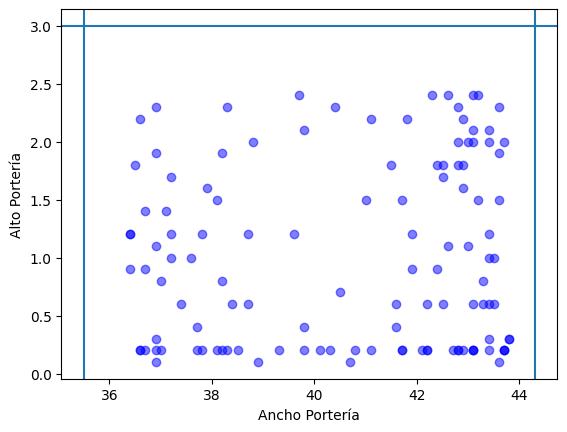

In [ ]:
plt.scatter(mas_prob.remainder__end_location_y, mas_prob.remainder__end_location_z, color='blue', label ='Tiros',alpha=0.5)
plt.xlabel('Ancho Portería')
plt.ylabel('Alto Portería')
plt.axhline(3.0)
plt.axvline(35.5)
plt.axvline(44.3)
plt.show()

In [ ]:
jugadores_prob = mas_prob.copy()
jugadores_prob.columns.to_list()

['cat__play_pattern_name_From Corner',
 'cat__play_pattern_name_From Counter',
 'cat__play_pattern_name_From Free Kick',
 'cat__play_pattern_name_From Goal Kick',
 'cat__play_pattern_name_From Keeper',
 'cat__play_pattern_name_From Kick Off',
 'cat__play_pattern_name_From Throw In',
 'cat__play_pattern_name_Regular Play',
 'cat__player_id_11388',
 'cat__player_id_131189',
 'cat__player_id_15822',
 'cat__player_id_23428',
 'cat__player_id_25458',
 'cat__player_id_26256',
 'cat__player_id_26288',
 'cat__player_id_26312',
 'cat__player_id_26369',
 'cat__player_id_26400',
 'cat__player_id_26774',
 'cat__player_id_275553',
 'cat__player_id_276020',
 'cat__player_id_29265',
 'cat__player_id_29574',
 'cat__player_id_3016',
 'cat__player_id_30458',
 'cat__player_id_30500',
 'cat__player_id_30736',
 'cat__player_id_30944',
 'cat__player_id_31956',
 'cat__player_id_33097',
 'cat__player_id_33126',
 'cat__player_id_337757',
 'cat__player_id_34349',
 'cat__player_id_35375',
 'cat__player_id_35544'

In [ ]:
columnas_jugadores = jugadores_prob.filter(like='cat__player_id_')
columna_recuperada = pd.from_dummies(columnas_jugadores)

In [ ]:
jugadores_prob['player_id'] = columna_recuperada.apply(lambda x: x.str.replace('cat__player_id_',''))
jugadores_prob.player_id

,player_id
0,8863
7,30500
8,8863
19,30736
24,35375
...,...
587,30736
588,30736
589,43555
594,50763


In [ ]:
jugadores_prob.columns

Index(['cat__play_pattern_name_From Corner',
       'cat__play_pattern_name_From Counter',
       'cat__play_pattern_name_From Free Kick',
       'cat__play_pattern_name_From Goal Kick',
       'cat__play_pattern_name_From Keeper',
       'cat__play_pattern_name_From Kick Off',
       'cat__play_pattern_name_From Throw In',
       'cat__play_pattern_name_Regular Play', 'cat__player_id_11388',
       'cat__player_id_131189',
       ...
       'remainder__follows_dribble', 'remainder__one_on_one',
       'remainder__open_goal', 'remainder__aerial_won',
       'remainder__first_time', 'remainder__shot_execution_xg',
       'remainder__shot_execution_xg_uplift', 'XGoT', 'dif', 'player_id'],
      dtype='object', length=106)

In [ ]:
jugadores_prob.drop(columns=[
    'cat__player_id_11388',
 'cat__player_id_131189',
 'cat__player_id_15822',
 'cat__player_id_23428',
 'cat__player_id_25458',
 'cat__player_id_26256',
 'cat__player_id_26288',
 'cat__player_id_26312',
 'cat__player_id_26369',
 'cat__player_id_26400',
 'cat__player_id_26774',
 'cat__player_id_275553',
 'cat__player_id_276020',
 'cat__player_id_29265',
 'cat__player_id_29574',
 'cat__player_id_3016',
 'cat__player_id_30458',
 'cat__player_id_30500',
 'cat__player_id_30736',
 'cat__player_id_30944',
 'cat__player_id_31956',
 'cat__player_id_33097',
 'cat__player_id_33126',
 'cat__player_id_337757',
 'cat__player_id_34349',
 'cat__player_id_35375',
 'cat__player_id_35544',
 'cat__player_id_35690',
 'cat__player_id_36167',
 'cat__player_id_37999',
 'cat__player_id_391381',
 'cat__player_id_401174',
 'cat__player_id_415002',
 'cat__player_id_430674',
 'cat__player_id_43555',
 'cat__player_id_436702',
 'cat__player_id_45608',
 'cat__player_id_458388',
 'cat__player_id_458389',
 'cat__player_id_46322',
 'cat__player_id_47467',
 'cat__player_id_50763',
 'cat__player_id_5556',
 'cat__player_id_6357',
 'cat__player_id_8863'
], inplace=True)

In [ ]:
columnas_jugadas = jugadores_prob.filter(like='cat__play_pattern_name_')
columna_recuperada_2 = pd.from_dummies(columnas_jugadas)
jugadores_prob['play_pattern_name'] = columna_recuperada_2.apply(lambda x: x.str.replace('cat__play_pattern_name_',''))

In [ ]:
columnas_jugadas = jugadores_prob.filter(like='cat__player_position_name_')
columna_recuperada_2 = pd.from_dummies(columnas_jugadas)
jugadores_prob['player_position_name'] = columna_recuperada_2.apply(lambda x: x.str.replace('cat__player_position_name_',''))

In [ ]:
jugadores_prob.columns

Index(['cat__play_pattern_name_From Corner',
       'cat__play_pattern_name_From Counter',
       'cat__play_pattern_name_From Free Kick',
       'cat__play_pattern_name_From Goal Kick',
       'cat__play_pattern_name_From Keeper',
       'cat__play_pattern_name_From Kick Off',
       'cat__play_pattern_name_From Throw In',
       'cat__play_pattern_name_Regular Play',
       'cat__player_position_name_Center Attacking Midfield',
       'cat__player_position_name_Center Back',
       'cat__player_position_name_Center Defensive Midfield',
       'cat__player_position_name_Center Forward',
       'cat__player_position_name_Left Attacking Midfield',
       'cat__player_position_name_Left Back',
       'cat__player_position_name_Left Center Back',
       'cat__player_position_name_Left Center Forward',
       'cat__player_position_name_Left Center Midfield',
       'cat__player_position_name_Left Defensive Midfield',
       'cat__player_position_name_Left Midfield',
       'cat__player_pos

In [ ]:
jugadores_prob.drop(columns=[
    'cat__play_pattern_name_From Corner',
       'cat__play_pattern_name_From Counter',
       'cat__play_pattern_name_From Free Kick',
       'cat__play_pattern_name_From Goal Kick',
       'cat__play_pattern_name_From Keeper',
       'cat__play_pattern_name_From Kick Off',
       'cat__play_pattern_name_From Throw In',
       'cat__play_pattern_name_Regular Play'
], inplace=True)

In [ ]:
jugadores_prob.drop(columns=[
    'cat__player_position_name_Center Attacking Midfield',
       'cat__player_position_name_Center Back',
       'cat__player_position_name_Center Defensive Midfield',
       'cat__player_position_name_Center Forward',
       'cat__player_position_name_Left Attacking Midfield',
       'cat__player_position_name_Left Back',
       'cat__player_position_name_Left Center Back',
       'cat__player_position_name_Left Center Forward',
       'cat__player_position_name_Left Center Midfield',
       'cat__player_position_name_Left Defensive Midfield',
       'cat__player_position_name_Left Midfield',
       'cat__player_position_name_Left Wing',
       'cat__player_position_name_Left Wing Back',
       'cat__player_position_name_Right Attacking Midfield',
       'cat__player_position_name_Right Back',
       'cat__player_position_name_Right Center Back',
       'cat__player_position_name_Right Center Forward',
       'cat__player_position_name_Right Center Midfield',
       'cat__player_position_name_Right Defensive Midfield',
       'cat__player_position_name_Right Midfield',
       'cat__player_position_name_Right Wing',
       'cat__player_position_name_Right Wing Back'
], inplace=True)

In [ ]:
jugadores_prob.columns

Index(['cat__type_name_Free Kick', 'cat__type_name_Open Play',
       'cat__technique_name_Backheel', 'cat__technique_name_Diving Header',
       'cat__technique_name_Half Volley', 'cat__technique_name_Lob',
       'cat__technique_name_Normal', 'cat__technique_name_Overhead Kick',
       'cat__technique_name_Volley', 'cat__body_part_name_Head',
       'cat__body_part_name_Left Foot', 'cat__body_part_name_Other',
       'cat__body_part_name_Right Foot',
       'cat__attacking_direction_left_to_right',
       'cat__attacking_direction_right_to_left', 'remainder__location_x',
       'remainder__location_y', 'remainder__location_y',
       'remainder__end_location_x', 'remainder__end_location_y',
       'remainder__end_location_z', 'remainder__follows_dribble',
       'remainder__one_on_one', 'remainder__open_goal',
       'remainder__aerial_won', 'remainder__first_time',
       'remainder__shot_execution_xg', 'remainder__shot_execution_xg_uplift',
       'XGoT', 'dif', 'player_id', 'play_

In [ ]:
tabla_dinamica_2 = pd.pivot_table(
    data=jugadores_prob,
    values='dif',
    index= 'play_pattern_name',
    columns='player_id',
    aggfunc='count',
    fill_value=0
)

In [ ]:
print(tabla_dinamica_2.to_markdown())

| play_pattern_name   |   131189 |   15822 |   23428 |   25458 |   26256 |   26288 |   26312 |   26369 |   26400 |   276020 |   29265 |   29574 |   3016 |   30458 |   30500 |   30736 |   30944 |   31956 |   33097 |   35375 |   36167 |   37999 |   401174 |   415002 |   43555 |   46322 |   47467 |   50763 |   8863 |
|:--------------------|---------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|--------:|--------:|-------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|--------:|--------:|--------:|-------:|
| From Corner         |        0 |       0 |       0 |       0 |       1 |       0 |       0 |       2 |       0 |        0 |       0 |       0 |      1 |       1 |       0 |       0 |       1 |       1 |       0 |       0 |       1 |       1 |        1 |        0 |       0 |       0 |       0 |       0 |      0 |
| From Counter        |        0 |       0 |       0

In [ ]:
columnas_type = jugadores_prob.filter(like='cat__type_name_')
columna_recuperada_3 = pd.from_dummies(columnas_type)
jugadores_prob['type_name_'] = columna_recuperada_3.apply(lambda x: x.str.replace('cat__type_name_',''))

In [ ]:
jugadores_prob.drop(columns=[
    'cat__type_name_Free Kick', 'cat__type_name_Open Play'
], inplace=True)

In [ ]:
columnas_technic = jugadores_prob.filter(like='cat__technique_name_')
columna_recuperada_4 = pd.from_dummies(columnas_technic)
jugadores_prob['technique_name_'] = columna_recuperada_4.apply(lambda x: x.str.replace('cat__technique_name_',''))

In [ ]:
jugadores_prob.drop(columns=[
    'cat__technique_name_Backheel', 'cat__technique_name_Diving Header',
       'cat__technique_name_Half Volley', 'cat__technique_name_Lob',
       'cat__technique_name_Normal', 'cat__technique_name_Overhead Kick',
       'cat__technique_name_Volley'
], inplace=True)

In [ ]:
jugadores_prob.columns

Index(['cat__body_part_name_Head', 'cat__body_part_name_Left Foot',
       'cat__body_part_name_Other', 'cat__body_part_name_Right Foot',
       'cat__attacking_direction_left_to_right',
       'cat__attacking_direction_right_to_left', 'remainder__location_x',
       'remainder__location_y', 'remainder__location_y',
       'remainder__end_location_x', 'remainder__end_location_y',
       'remainder__end_location_z', 'remainder__follows_dribble',
       'remainder__one_on_one', 'remainder__open_goal',
       'remainder__aerial_won', 'remainder__first_time',
       'remainder__shot_execution_xg', 'remainder__shot_execution_xg_uplift',
       'XGoT', 'dif', 'player_id', 'play_pattern_name', 'player_position_name',
       'type_name_', 'technique_name_'],
      dtype='object')

In [ ]:
columnas = ['body_part_name_', 'attacking_direction_']

In [ ]:
jugadores_prob.filter(like='cat__attacking_direction_').columns

Index(['cat__attacking_direction_left_to_right', 'cat__attacking_direction_right_to_left'], dtype='object')

In [ ]:
def columnas_drop(col_name):
  test = 'cat__'+col_name
  columnas_technic = jugadores_prob.filter(like=test)
  print(columnas_technic.columns)
  columna_recuperada = pd.from_dummies(columnas_technic)
  jugadores_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
  lista = columnas_technic.columns.to_list()
  for col in range(0,len(lista)):
    lista[col]='cat__' + lista[col]
  jugadores_prob.drop(columns=lista, inplace=True)

In [ ]:
# Corregimos la función columnas_drop directamente para evitar el prefijo duplicado
def columnas_drop_corregida(col_name):
  test = 'cat__' + col_name
  columnas_technic = jugadores_prob.filter(like=test)
  print(columnas_technic.columns)
  columna_recuperada = pd.from_dummies(columnas_technic)
  jugadores_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
  lista = columnas_technic.columns.to_list()
  # No agregamos 'cat__' de nuevo porque ya lo contienen
  jugadores_prob.drop(columns=lista, inplace=True)

for col in columnas:
  columnas_drop_corregida(col)

Index(['cat__body_part_name_Head', 'cat__body_part_name_Left Foot',
       'cat__body_part_name_Other', 'cat__body_part_name_Right Foot'],
      dtype='object')
Index(['cat__attacking_direction_left_to_right', 'cat__attacking_direction_right_to_left'], dtype='object')


In [ ]:
jugadores_prob.columns

Index(['remainder__location_x', 'remainder__location_y',
       'remainder__location_y', 'remainder__end_location_x',
       'remainder__end_location_y', 'remainder__end_location_z',
       'remainder__follows_dribble', 'remainder__one_on_one',
       'remainder__open_goal', 'remainder__aerial_won',
       'remainder__first_time', 'remainder__shot_execution_xg',
       'remainder__shot_execution_xg_uplift', 'XGoT', 'dif', 'player_id',
       'play_pattern_name', 'player_position_name', 'type_name_',
       'technique_name_', 'body_part_name_', 'attacking_direction_'],
      dtype='object')

In [ ]:
tabla_dinamica_3 = pd.pivot_table(
    data=jugadores_prob,
    values='dif',
    index= 'body_part_name_',
    columns='player_id',
    aggfunc='count',
    fill_value=0
)

In [ ]:
print(tabla_dinamica_3.to_markdown())

| body_part_name_   |   131189 |   15822 |   23428 |   25458 |   26256 |   26288 |   26312 |   26369 |   26400 |   276020 |   29265 |   29574 |   3016 |   30458 |   30500 |   30736 |   30944 |   31956 |   33097 |   35375 |   36167 |   37999 |   401174 |   415002 |   43555 |   46322 |   47467 |   50763 |   8863 |
|:------------------|---------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|--------:|--------:|-------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|--------:|--------:|--------:|-------:|
| Head              |        0 |       0 |       0 |       0 |       1 |       0 |       0 |       0 |       2 |        0 |       0 |       0 |      0 |       0 |       0 |       0 |       1 |       0 |       0 |       0 |       2 |       1 |        2 |        0 |       1 |       0 |       0 |       0 |      0 |
| Left Foot         |        1 |       2 |       1 |      

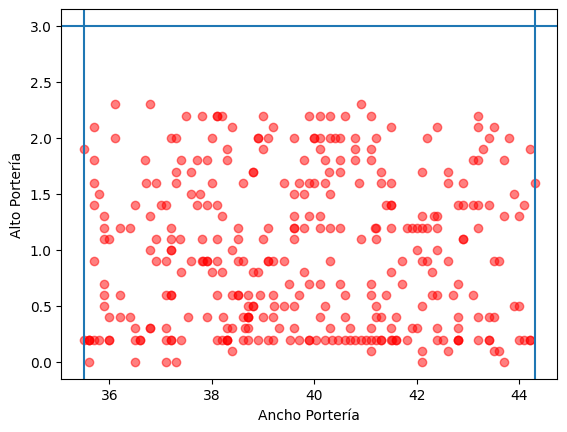

In [ ]:
plt.scatter(menos_prob.remainder__end_location_y, menos_prob.remainder__end_location_z, color='red', label ='Tiros',alpha=0.5)
plt.xlabel('Ancho Portería')
plt.ylabel('Alto Portería')
plt.axhline(3.0)
plt.axvline(35.5)
plt.axvline(44.3)
plt.show()

In [ ]:
categoricas= ['play_pattern_name_','player_id_','player_position_name_','type_name_',
              'technique_name_','body_part_name_','attacking_direction_']

In [ ]:
def columnas_drop_corregida_2(col_name):
  test = 'cat__' + col_name
  columnas_technic = menos_prob.filter(like=test)
  # print(columnas_technic.columns)
  columna_recuperada = pd.from_dummies(columnas_technic)
  menos_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
  lista = columnas_technic.columns.to_list()
  columnas_technic= columnas_technic.columns.to_list()
  menos_prob.drop(columns=columnas_technic, inplace=True)
  # No agregamos 'cat__' de nuevo porque ya lo contiene

In [ ]:
for col in categoricas:
  columnas_drop_corregida_2(col)

/tmp/ipykernel_63822/3341151145.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  menos_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
/tmp/ipykernel_63822/3341151145.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  menos_prob.drop(columns=columnas_technic, inplace=True)
/tmp/ipykernel_63822/3341151145.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/

In [ ]:
menos_prob.columns

Index(['remainder__location_x', 'remainder__location_y',
       'remainder__location_y', 'remainder__end_location_x',
       'remainder__end_location_y', 'remainder__end_location_z',
       'remainder__follows_dribble', 'remainder__one_on_one',
       'remainder__open_goal', 'remainder__aerial_won',
       'remainder__first_time', 'remainder__shot_execution_xg',
       'remainder__shot_execution_xg_uplift', 'XGoT', 'dif',
       'play_pattern_name_', 'player_id_', 'player_position_name_',
       'type_name_', 'technique_name_', 'body_part_name_',
       'attacking_direction_'],
      dtype='object')

In [ ]:
tabla_dinamica_4 = pd.pivot_table(
    data=menos_prob,
    values='dif',
    index= 'body_part_name_',
    columns='player_id_',
    aggfunc='count',
    fill_value=0
)
print(tabla_dinamica_4.to_markdown())

| body_part_name_   |   11388 |   131189 |   15822 |   23428 |   25458 |   26256 |   26288 |   26312 |   26369 |   26400 |   26774 |   275553 |   276020 |   29265 |   29574 |   3016 |   30458 |   30500 |   30736 |   30944 |   31956 |   33097 |   33126 |   337757 |   34349 |   35375 |   35544 |   35690 |   36167 |   37999 |   391381 |   401174 |   43555 |   436702 |   45608 |   458389 |   46322 |   47467 |   50763 |   5556 |   6357 |   8863 |
|:------------------|--------:|---------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|--------:|-------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|--------:|--------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|---------:|--------:|---------:|--------:|--------:|--------:|-------:|-------:|-------:|
| Head              |       1 |        1 |       0 |       2 |       1 |       2 |       1 |       0 |      

In [ ]:
jugadores_df[jugadores_df.player_id== 35375]['player_name'].iloc[0]

'Julián Andrés Quiñones Quiñones'

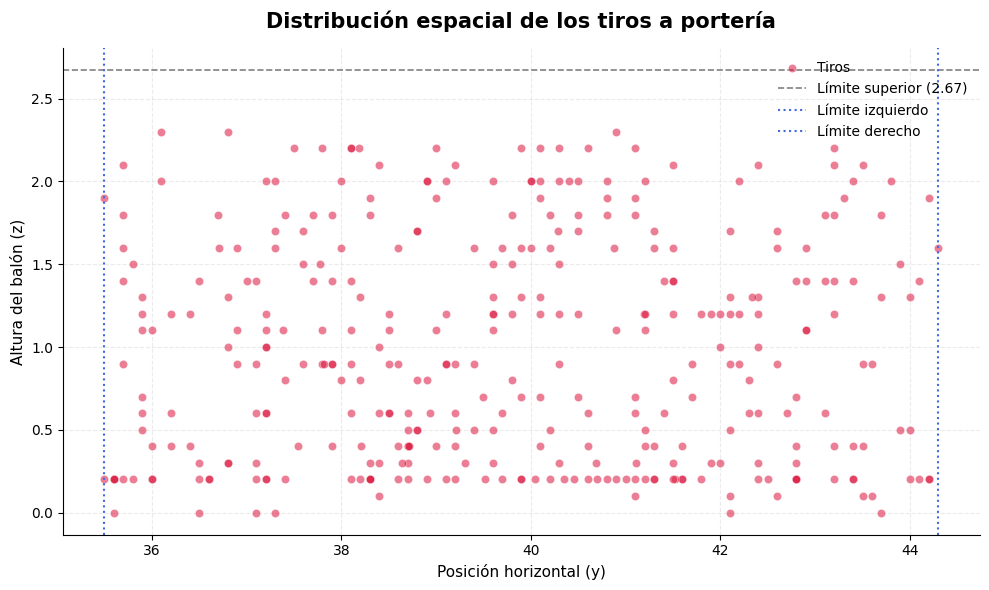

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

# Dispersión de los tiros
ax.scatter(
    menos_prob['remainder__end_location_y'],
    menos_prob['remainder__end_location_z'],
    color='crimson',
    label='Tiros',
    alpha=0.55,
    s=35,
    edgecolors='white',
    linewidths=0.4
)

# Líneas de referencia
ax.axhline(
    y=2.67,
    color='gray',
    linestyle='--',
    linewidth=1.2,
    label='Límite superior (2.67)'
)

ax.axvline(
    x=35.5,
    color='royalblue',
    linestyle=':',
    linewidth=1.5,
    label='Límite izquierdo'
)

ax.axvline(
    x=44.3,
    color='royalblue',
    linestyle=':',
    linewidth=1.5,
    label='Límite derecho'
)

# Títulos y etiquetas
ax.set_title(
    'Distribución espacial de los tiros a portería',
    fontsize=15,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Posición horizontal (y)', fontsize=11)
ax.set_ylabel('Altura del balón (z)', fontsize=11)

# Estilo
ax.grid(True, linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='best')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
def columnas_drop_corregida_3(col_name):
  test = 'cat__' + col_name
  columnas_technic = mas_prob.filter(like=test)
  # print(columnas_technic.columns)
  columna_recuperada = pd.from_dummies(columnas_technic)
  mas_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
  lista = columnas_technic.columns.to_list()
  columnas_technic= columnas_technic.columns.to_list()
  mas_prob.drop(columns=columnas_technic, inplace=True)
  # No agregamos 'cat__' de nuevo porque ya lo contiene

In [ ]:
for col in categoricas:
  columnas_drop_corregida_3(col)

/tmp/ipykernel_63822/4025109016.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mas_prob[col_name] = columna_recuperada.apply(lambda x: x.str.replace('cat__'+col_name,''))
/tmp/ipykernel_63822/4025109016.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mas_prob.drop(columns=columnas_technic, inplace=True)
/tmp/ipykernel_63822/4025109016.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pand

In [ ]:
mas_prob.columns

Index(['remainder__location_x', 'remainder__location_y',
       'remainder__location_y', 'remainder__end_location_x',
       'remainder__end_location_y', 'remainder__end_location_z',
       'remainder__follows_dribble', 'remainder__one_on_one',
       'remainder__open_goal', 'remainder__aerial_won',
       'remainder__first_time', 'remainder__shot_execution_xg',
       'remainder__shot_execution_xg_uplift', 'XGoT', 'dif',
       'play_pattern_name_', 'player_id_', 'player_position_name_',
       'type_name_', 'technique_name_', 'body_part_name_',
       'attacking_direction_'],
      dtype='object')

In [ ]:
def evaluacion_jugador(player_id):
  fig, ax = plt.subplots(figsize=(10, 6))

  # Dispersión de los tiros
  ax.scatter(
      menos_prob[menos_prob.player_id_==player_id]['remainder__end_location_y'],
      menos_prob[menos_prob.player_id_==player_id]['remainder__end_location_z'],
      color='crimson',
      label='Tiros con menor XGOT',
      alpha=0.55,
      s=35,
      edgecolors='white',
      linewidths=0.4
  )
  ax.scatter(
      mas_prob[mas_prob.player_id_==player_id]['remainder__end_location_y'],
      mas_prob[mas_prob.player_id_==player_id]['remainder__end_location_z'],
      color='blue',
      label='Tiros con mayor XGOT',
      alpha=0.55,
      s=35,
      edgecolors='white',
      linewidths=0.4
  )

  # Líneas de referencia
  ax.axhline(
      y=2.67,
      color='gray',
      linestyle='--',
      linewidth=1.2,
      label='Límite superior (2.67)'
  )

  ax.axvline(
      x=35.5,
      color='royalblue',
      linestyle=':',
      linewidth=1.5,
      label='Límite izquierdo'
  )

  ax.axvline(
      x=44.3,
      color='royalblue',
      linestyle=':',
      linewidth=1.5,
      label='Límite derecho'
  )

  jugador = jugadores_df[jugadores_df.player_id== int(player_id)]['player_name'].iloc[0]

  # Títulos y etiquetas
  ax.set_title(
      f'Distribución espacial de los tiros a portería de {jugador}',
      fontsize=15,
      fontweight='bold',
      pad=15
  )
  ax.set_xlabel('Posición horizontal (y)', fontsize=11)
  ax.set_ylabel('Altura del balón (z)', fontsize=11)

  # Estilo
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.set_axisbelow(True)
  ax.legend(frameon=False, loc='best')
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  plt.tight_layout()
  plt.show()

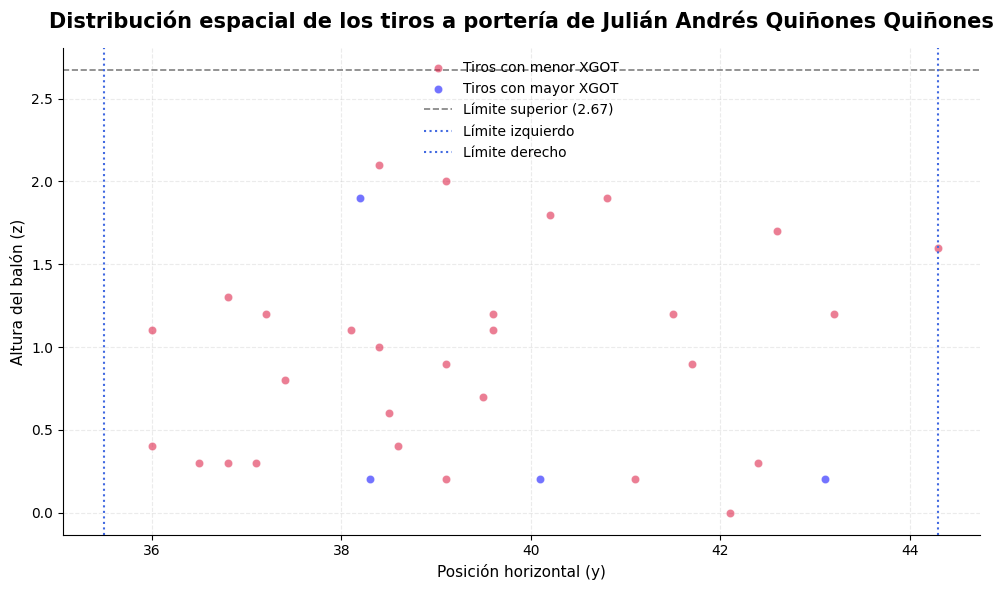

In [ ]:
evaluacion_jugador('35375')

In [ ]:
df_tiros = df[[
    'possession_team_name', 'play_pattern_name',
    'player_id', 'player_position_name',
    'location_x', 'location_y',
    'end_location_x', 'end_location_y', 'end_location_z',
    'follows_dribble', 'one_on_one', 'open_goal',
    'outcome_name', 'type_name', 'technique_name',
    'body_part_name', 'aerial_won', 'first_time',
    'penalty', 'shot_execution_xg',
    'shot_execution_xg_uplift', 'attacking_direction'
]]

In [ ]:
X = df_procesado.drop(columns=[
    'remainder__Goal',
    'remainder__shot_execution_xg',
    'remainder__shot_execution_xg_uplift'
])

y = df_procesado['remainder__Goal']

In [ ]:
from sklearn.metrics import brier_score_loss, log_loss,

In [ ]:
# Probabilidad estimada por nuestro modelo
p_gol = modelo_rf.predict_proba(X_test)[:, 1]

evaluacion = X_test[
    ['remainder__end_location_y', 'remainder__end_location_z']
].copy()

evaluacion['p_gol_modelada'] = p_gol
evaluacion['shot_execution_xg'] = df_procesado.loc[
    X_test.index, 'remainder__shot_execution_xg'
]
evaluacion['gol_real'] = y_test

# Identificar al jugador a partir de las variables dummy
columnas_player = X_test.filter(like='cat__player_id_')

evaluacion['player_id'] = (
    columnas_player.idxmax(axis=1)
    .str.replace('cat__player_id_', '', regex=False)
)

# Comparación entre probabilidades
evaluacion['diferencia'] = (
    evaluacion['p_gol_modelada'] - evaluacion['shot_execution_xg']
)

print(f"Remates evaluados: {len(evaluacion)}")
print(f"Brier Score: {brier_score_loss(y_test, p_gol):.4f}")
print(f"Log-loss: {log_loss(y_test, p_gol):.4f}")

print(evaluacion.head().to_markdown())

Remates evaluados: 121
Brier Score: 0.0247
Log-loss: 0.1285
|     |   remainder__end_location_y |   remainder__end_location_z |   p_gol_modelada |   shot_execution_xg |   gol_real |   player_id |   diferencia |
|----:|----------------------------:|----------------------------:|-----------------:|--------------------:|-----------:|------------:|-------------:|
| 289 |                        42.7 |                         0.2 |             0.54 |           0.01756   |          1 |       47467 |    0.52244   |
| 366 |                        38.8 |                         2   |             0.75 |           0.168575  |          1 |       26400 |    0.581425  |
| 480 |                        40.9 |                         0.8 |             0.03 |           0.0123538 |          0 |       43555 |    0.0176462 |
|  91 |                        39.6 |                         1.3 |             0.89 |           0.909056  |          1 |       26288 |   -0.0190563 |
| 293 |                        37.

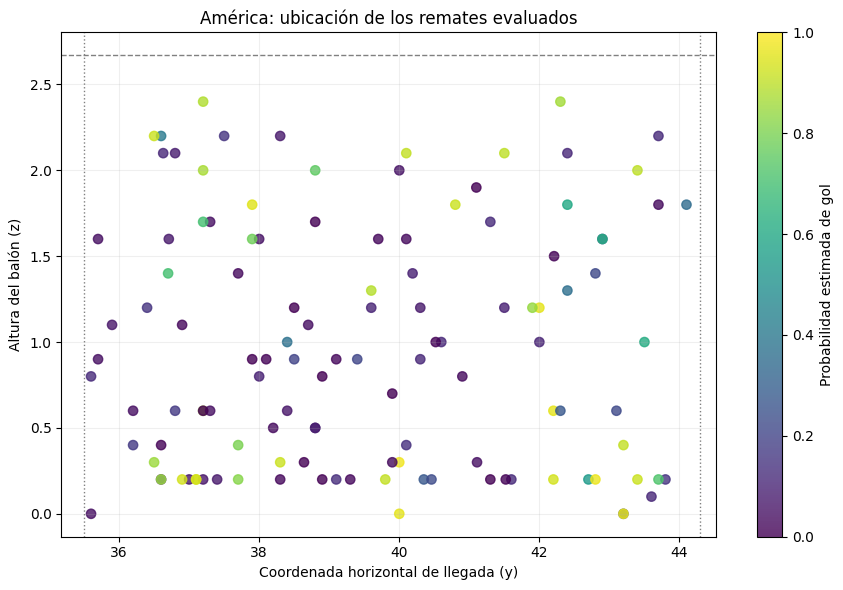

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

puntos = ax.scatter(
    evaluacion['remainder__end_location_y'],
    evaluacion['remainder__end_location_z'],
    c=evaluacion['p_gol_modelada'],
    cmap='viridis',
    vmin=0,
    vmax=1,
    alpha=0.8,
    s=45
)

fig.colorbar(puntos, ax=ax, label='Probabilidad estimada de gol')
ax.axhline(2.67, color='gray', linestyle='--', linewidth=1)
ax.axvline(35.5, color='gray', linestyle=':', linewidth=1)
ax.axvline(44.3, color='gray', linestyle=':', linewidth=1)

ax.set(
    title='América: ubicación de los remates evaluados',
    xlabel='Coordenada horizontal de llegada (y)',
    ylabel='Altura del balón (z)'
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

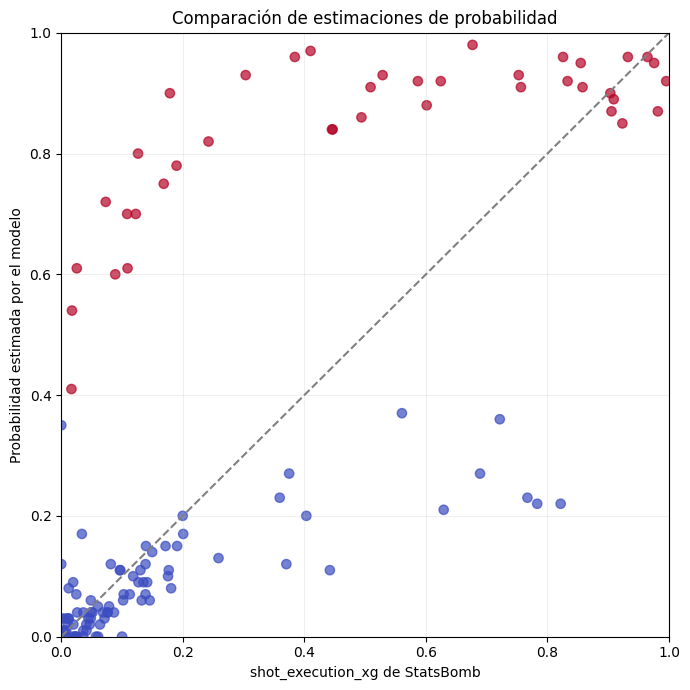

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    evaluacion['shot_execution_xg'],
    evaluacion['p_gol_modelada'],
    c=evaluacion['gol_real'],
    cmap='coolwarm',
    alpha=0.7,
    s=45
)

ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(
    title='Comparación de estimaciones de probabilidad',
    xlabel='shot_execution_xg de StatsBomb',
    ylabel='Probabilidad estimada por el modelo',
    xlim=(0, 1),
    ylim=(0, 1)
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
nombres = jugadores_df.copy()
nombres['player_id'] = nombres['player_id'].astype(str)

resumen_jugadores = (
    evaluacion.groupby('player_id')
    .agg(
        remates=('gol_real', 'size'),
        goles=('gol_real', 'sum'),
        prob_modelo_media=('p_gol_modelada', 'mean'),
        statsbomb_media=('shot_execution_xg', 'mean')
    )
    .reset_index()
    .merge(nombres, on='player_id', how='left')
    .sort_values('remates', ascending=False)
)

print(resumen_jugadores.head(15).to_markdown())

|    |   player_id |   remates |   goles |   prob_modelo_media |   statsbomb_media | player_name                        |
|---:|------------:|----------:|--------:|--------------------:|------------------:|:-----------------------------------|
| 11 |       30458 |        14 |       4 |            0.325714 |         0.281078  | Alejandro Zendejas Saavedra        |
|  7 |       26400 |         9 |       3 |            0.438889 |         0.380863  | Henry Josué Martín Mex             |
| 13 |       30736 |         9 |       3 |            0.348889 |         0.24317   | Paul Brian Rodríguez Bravo         |
| 26 |       47467 |         9 |       4 |            0.391111 |         0.297739  | Álvaro Fidalgo Fernández           |
|  6 |       26369 |         8 |       3 |            0.36125  |         0.256447  | Diego Alfonso Valdés Contreras     |
| 14 |       30944 |         7 |       4 |            0.551429 |         0.500318  | Víctor Alejandro Dávila Zavala     |
| 18 |       35375 |    

In [ ]:
print(resumen_jugadores.head(15).to_html())

<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>player_id</th>
      <th>remates</th>
      <th>goles</th>
      <th>prob_modelo_media</th>
      <th>statsbomb_media</th>
      <th>player_name</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>11</th>
      <td>30458</td>
      <td>14</td>
      <td>4.0</td>
      <td>0.325714</td>
      <td>0.281078</td>
      <td>Alejandro Zendejas Saavedra</td>
    </tr>
    <tr>
      <th>7</th>
      <td>26400</td>
      <td>9</td>
      <td>3.0</td>
      <td>0.438889</td>
      <td>0.380863</td>
      <td>Henry Josué Martín Mex</td>
    </tr>
    <tr>
      <th>13</th>
      <td>30736</td>
      <td>9</td>
      <td>3.0</td>
      <td>0.348889</td>
      <td>0.243170</td>
      <td>Paul Brian Rodríguez Bravo</td>
    </tr>
    <tr>
      <th>26</th>
      <td>47467</td>
      <td>9</td>
      <td>4.0</td>
      <td>0.391111</td>
      <td>0.297739</td>
      <td>Álvaro Fidalgo Fern